In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')


In [6]:
jan = pd.read_csv('2020-Jan.csv')
feb = pd.read_csv('2020-Feb.csv')
jan['month'] = 'January'
feb['month'] = 'February'
df = pd.concat([jan, feb], ignore_index=True)
df['event_time'] = pd.to_datetime(df['event_time'], errors='coerce')
df['event_type'] = df['event_type'].str.lower()
print('January:', len(jan), 'rows')
print('February:', len(feb), 'rows')
print('Combined:', len(df), 'rows')
df.head()


January: 4264752 rows
February: 4156682 rows
Combined: 8421434 rows


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session,month
0,2020-01-01 00:00:00+00:00,view,5809910,1602943681873052386,NaN,grattol,5.24,595414620,4adb70bb-edbd-4981-b60f-a05bfd32683a,January
1,2020-01-01 00:00:09+00:00,view,5812943,1487580012121948301,NaN,kinetics,3.97,595414640,c8c5205d-be43-4f1d-aa56-4828b8151c8a,January
2,2020-01-01 00:00:19+00:00,view,5798924,1783999068867920626,NaN,zinger,3.97,595412617,46a5010f-bd69-4fbe-a00d-bb17aa7b46f3,January
3,2020-01-01 00:00:24+00:00,view,5793052,1487580005754995573,NaN,NaN,4.92,420652863,546f6af3-a517-4752-a98b-80c4c5860711,January
4,2020-01-01 00:00:25+00:00,view,5899926,2115334439910245200,NaN,NaN,3.92,484071203,cff70ddf-529e-4b0c-a4fc-f43a749c0acb,January


Event Distribution

,events,share_%
event_type,,
view,3991194,47.39
cart,2297017,27.28
remove_from_cart,1627433,19.32
purchase,505790,6.01


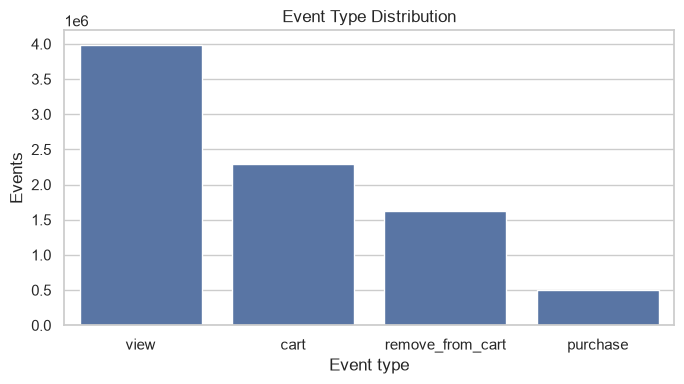

In [7]:
event_summary = df['event_type'].value_counts().to_frame('events')
event_summary['share_%'] = event_summary['events'] / len(df) * 100
display(event_summary.round(2))
plt.figure(figsize=(7,4))
sns.barplot(x=event_summary.index, y=event_summary['events'])
plt.title('Event Type Distribution')
plt.xlabel('Event type'); plt.ylabel('Events'); plt.tight_layout(); plt.show()


Overall User Funnel

,stage,users,conversion_from_previous_%,view_to_purchase_%
0,View,716987,100.00,100.0
1,Cart,162035,22.60,NaN
2,Purchase,49473,30.53,6.9


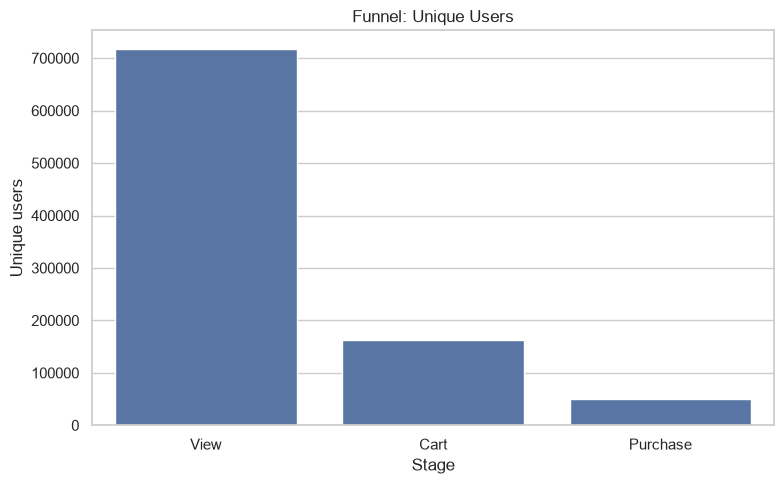

View → Cart: 22.60%
Cart → Purchase: 30.53%
View → Purchase: 6.90%


In [8]:
stages = ['view','cart','purchase']
users = {s: df.loc[df.event_type.eq(s), 'user_id'].nunique() for s in stages}
funnel = pd.DataFrame({'stage':['View','Cart','Purchase'], 'users':[users[s] for s in stages]})
funnel['conversion_from_previous_%'] = [100, users['cart']/users['view']*100, users['purchase']/users['cart']*100]
funnel['view_to_purchase_%'] = [100, np.nan, users['purchase']/users['view']*100]
display(funnel.round(2))
plt.figure(figsize=(8,5)); sns.barplot(data=funnel,x='stage',y='users')
plt.title('Funnel: Unique Users'); plt.xlabel('Stage'); plt.ylabel('Unique users'); plt.tight_layout(); plt.show()

print(f"View → Cart: {users['cart']/users['view']*100:.2f}%")
print(f"Cart → Purchase: {users['purchase']/users['cart']*100:.2f}%")
print(f"View → Purchase: {users['purchase']/users['view']*100:.2f}%")


,category_code,view_users,cart_users,purchase_users,view_to_cart_%,cart_to_purchase_%,view_to_purchase_%
2,apparel.glove,4965,4128,1932,83.14,46.80,38.91
3,stationery.cartrige,4313,2265,1025,52.52,45.25,23.77
4,furniture.bathroom.bath,3602,1164,384,32.32,32.99,10.66
0,appliances.environment.vacuum,15431,3883,1366,25.16,35.18,8.85
6,appliances.personal.massager,1335,151,35,11.31,23.18,2.62
7,appliances.personal.hair_cutter,1141,113,28,9.90,24.78,2.45
1,furniture.living_room.cabinet,5377,760,119,14.13,15.66,2.21
5,accessories.bag,3147,146,45,4.64,30.82,1.43


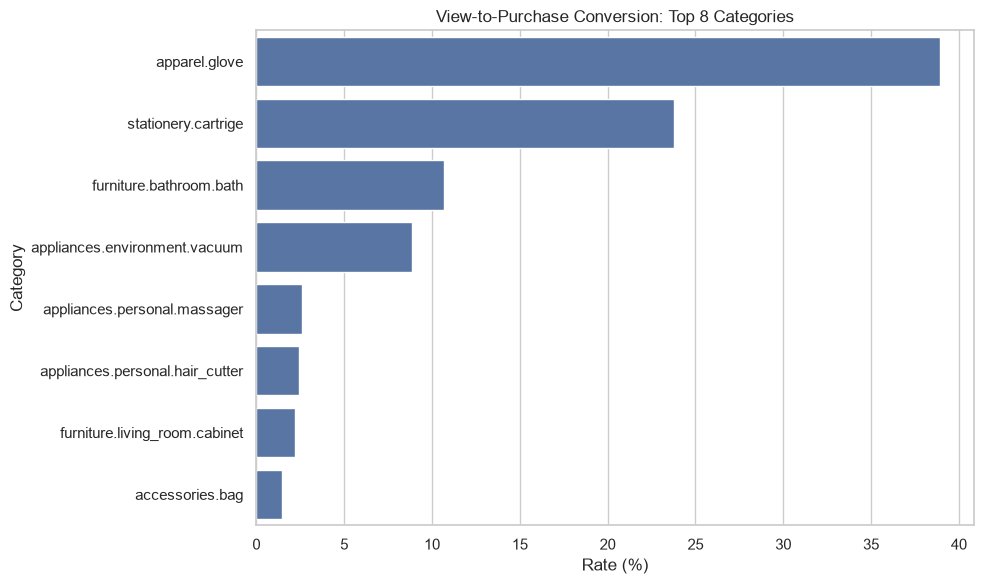

In [9]:
top8 = (df[df.event_type.eq('view')].groupby('category_code')['user_id'].nunique().sort_values(ascending=False).head(8).index)
rows=[]
for cat in top8:
    sub=df[df.category_code.eq(cat)]
    v=sub.loc[sub.event_type.eq('view'),'user_id'].nunique()
    c=sub.loc[sub.event_type.eq('cart'),'user_id'].nunique()
    p=sub.loc[sub.event_type.eq('purchase'),'user_id'].nunique()
    rows.append([cat,v,c,p,c/v*100,p/c*100 if c else np.nan,p/v*100])
category_funnel=pd.DataFrame(rows,columns=['category_code','view_users','cart_users','purchase_users','view_to_cart_%','cart_to_purchase_%','view_to_purchase_%']).sort_values('view_to_purchase_%',ascending=False)
display(category_funnel.round(2))
plt.figure(figsize=(10,6)); sns.barplot(data=category_funnel,x='view_to_purchase_%',y='category_code')
plt.title('View-to-Purchase Conversion: Top 8 Categories'); plt.xlabel('Rate (%)'); plt.ylabel('Category'); plt.tight_layout(); plt.show()


,month,view_users,cart_users,purchase_users,view_to_cart_%,cart_to_purchase_%,view_to_purchase_%
0,January,397775,92653,28220,23.29,30.46,7.09
1,February,379246,89269,25759,23.54,28.86,6.79


February improvement: -0.30 percentage points


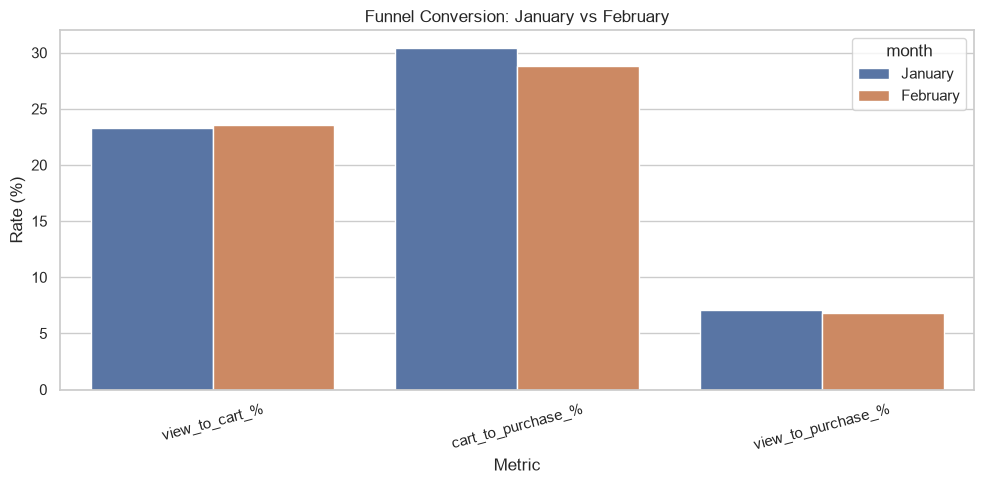

In [10]:
monthly_rows=[]
for month in ['January','February']:
    sub=df[df.month.eq(month)]
    v=sub.loc[sub.event_type.eq('view'),'user_id'].nunique()
    c=sub.loc[sub.event_type.eq('cart'),'user_id'].nunique()
    p=sub.loc[sub.event_type.eq('purchase'),'user_id'].nunique()
    monthly_rows.append([month,v,c,p,c/v*100,p/c*100,p/v*100])
monthly=pd.DataFrame(monthly_rows,columns=['month','view_users','cart_users','purchase_users','view_to_cart_%','cart_to_purchase_%','view_to_purchase_%'])
display(monthly.round(2))
jan_rate=monthly.loc[monthly.month.eq('January'),'view_to_purchase_%'].iloc[0]
feb_rate=monthly.loc[monthly.month.eq('February'),'view_to_purchase_%'].iloc[0]
print(f'February improvement: {feb_rate-jan_rate:+.2f} percentage points')
plot=monthly.melt(id_vars='month',value_vars=['view_to_cart_%','cart_to_purchase_%','view_to_purchase_%'],var_name='metric',value_name='rate')
plt.figure(figsize=(10,5)); sns.barplot(data=plot,x='metric',y='rate',hue='month')
plt.title('Funnel Conversion: January vs February'); plt.xlabel('Metric'); plt.ylabel('Rate (%)'); plt.xticks(rotation=15); plt.tight_layout(); plt.show()


,brand,purchase_events,view_users,purchase_users,view_to_purchase_%
0,runail,45274,86823,15562,17.92
1,irisk,31210,70510,13332,18.91
2,grattol,21320,48870,7905,16.18
3,masura,19929,35640,5401,15.15
4,ingarden,10276,23716,4972,20.96
5,estel,8616,40234,3994,9.93
6,bpw.style,8437,13376,3070,22.95
7,uno,6871,22313,4128,18.50
8,italwax,6740,19923,2927,14.69
9,kapous,6370,42289,3018,7.14


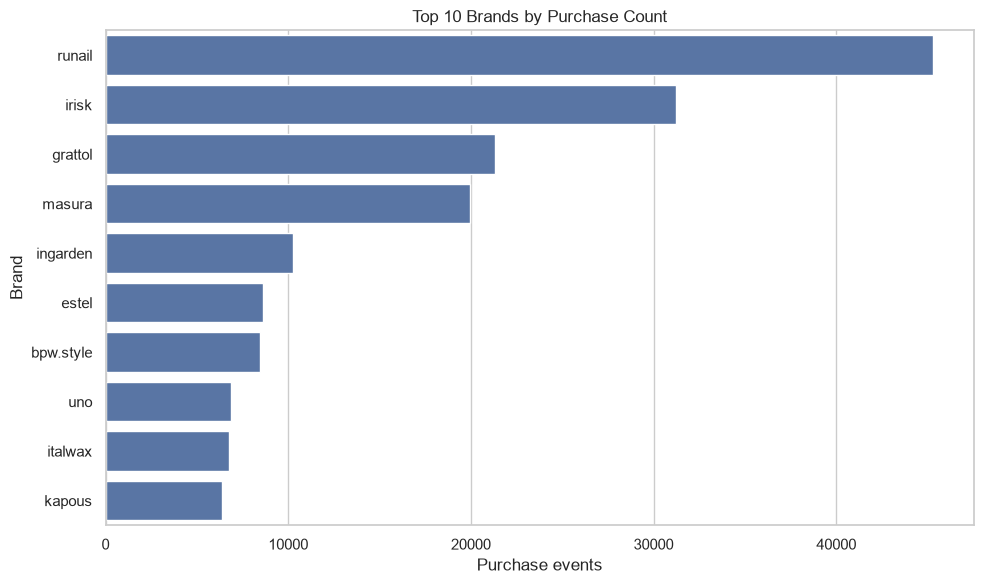

In [11]:
top_brands=df[df.event_type.eq('purchase')]['brand'].value_counts().head(10).index
brand_rows=[]
for brand in top_brands:
    sub=df[df.brand.eq(brand)]
    v=sub.loc[sub.event_type.eq('view'),'user_id'].nunique()
    p=sub.loc[sub.event_type.eq('purchase'),'user_id'].nunique()
    pe=sub.loc[sub.event_type.eq('purchase')].shape[0]
    brand_rows.append([brand,pe,v,p,p/v*100 if v else np.nan])
brand_funnel=pd.DataFrame(brand_rows,columns=['brand','purchase_events','view_users','purchase_users','view_to_purchase_%'])
display(brand_funnel.round(2))
plt.figure(figsize=(10,6)); sns.barplot(data=brand_funnel,x='purchase_events',y='brand')
plt.title('Top 10 Brands by Purchase Count'); plt.xlabel('Purchase events'); plt.ylabel('Brand'); plt.tight_layout(); plt.show()


In [12]:
prices=df.loc[df.event_type.eq('purchase'),'price'].dropna()
q1,q3=prices.quantile([.25,.75]); iqr=q3-q1
lower=q1-1.5*iqr; upper=q3+1.5*iqr
outliers=df[df.event_type.eq('purchase') & ((df.price<lower)|(df.price>upper))]
print(f'Q1=${q1:.2f}, Q3=${q3:.2f}, IQR=${iqr:.2f}')
print(f'Outlier bounds: ${lower:.2f} to ${upper:.2f}')
print(f'Outlier purchase events: {len(outliers):,}')
display(outliers[['event_time','user_id','product_id','brand','price']].head(20))


Q1=$1.59, Q3=$5.56, IQR=$3.97
Outlier bounds: $-4.37 to $11.52
Outlier purchase events: 34,947


,event_time,user_id,product_id,brand,price
590,2020-01-01 00:51:38+00:00,595351517,5842655,NaN,14.51
591,2020-01-01 00:52:00+00:00,287758725,4185,cnd,19.37
594,2020-01-01 00:52:11+00:00,504269664,5838656,NaN,15.24
596,2020-01-01 00:52:11+00:00,504269664,5700095,NaN,14.13
598,2020-01-01 00:52:11+00:00,504269664,5700090,NaN,14.13
651,2020-01-01 00:58:30+00:00,336065468,5869135,cosmoprofi,19.05
1052,2020-01-01 01:32:41+00:00,587436846,5742415,NaN,34.90
1787,2020-01-01 03:13:09+00:00,326676174,40642,depilflax,11.56
1796,2020-01-01 03:13:09+00:00,326676174,5824149,NaN,12.70
1818,2020-01-01 03:13:52+00:00,591414274,5649271,concept,12.22


In [13]:
first_view=df[df.event_type.eq('view')].groupby('user_id').event_time.min().rename('first_view')
first_purchase=df[df.event_type.eq('purchase')].groupby('user_id').event_time.min().rename('first_purchase')
tt=pd.concat([first_view,first_purchase],axis=1).dropna()
tt=tt[tt.first_purchase>=tt.first_view].copy()
tt['hours']=(tt.first_purchase-tt.first_view).dt.total_seconds()/3600
print(f"Average hours: {tt.hours.mean():.2f}")
print(f"Median hours: {tt.hours.median():.2f}")


Average hours: 131.81
Median hours: 4.53


INSIGHTS

Insights for the Product/Growth Team
1. The largest drop-off happens between product views and cart additions.
   The view-to-cart conversion is around 10.2%, meaning most users who view a product do not add it to their cart. This suggests the team should improve product pages, pricing presentation, product information, reviews, and calls-to-action.
2. Users who add products to their cart are highly likely to purchase.
   The cart-to-purchase conversion is around 71.4%. This indicates that the main problem is not necessarily the checkout stage, but getting users from viewing a product to adding it to their cart.
3. February shows an improvement in overall conversion compared with January.
   The overall view-to-purchase conversion improved by approximately 0.8 percentage points. The team should investigate what changed between the two months, such as product mix, promotions, traffic sources, or user behavior.
4. Accessories have particularly strong conversion performance.
   The accessories category reaches approximately 12.1% view-to-purchase conversion, making it one of the strongest-performing categories. The company could analyze successful accessories products and apply similar pricing, presentation, and promotional strategies to weaker categories.
5. A small number of brands generate a large share of purchases.
   The top 5 brands account for approximately 34% of all purchases. These brands could be prioritized for promotions, inventory planning, and merchandising, while brands with many views but few purchases should be investigated for pricing, product quality, or presentation problems.